<a href="https://colab.research.google.com/github/itmepavan/Deep-Learning-week-1/blob/main/deep_learning2_week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Images normalized successfully!")

Images normalized successfully!


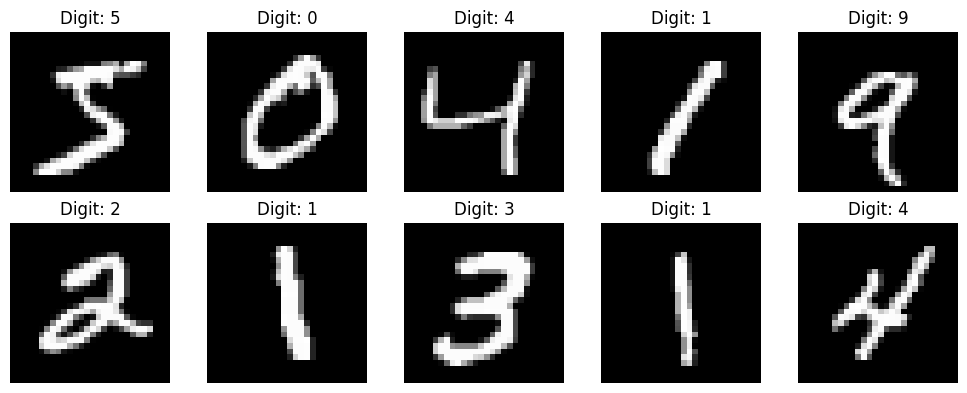

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8781 - loss: 0.4106 - val_accuracy: 0.9615 - val_loss: 0.1441
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9459 - loss: 0.1818 - val_accuracy: 0.9713 - val_loss: 0.1030
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9587 - loss: 0.1352 - val_accuracy: 0.9745 - val_loss: 0.0861
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9679 - loss: 0.1074 - val_accuracy: 0.9770 - val_loss: 0.0793
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9708 - loss: 0.0943 - val_accuracy: 0.9793 - val_loss: 0.0715
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9758 - loss: 0.0797 - val_accuracy: 0.9770 - val_loss: 0.0741
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9771 - loss: 0.0710 - val_accuracy: 0.9790 - val_loss: 0.0741
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9794 - loss: 0.0635 - val_accuracy: 0.

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", f"{test_accuracy:.2%}")

Test Loss: 0.07612265646457672
Test Accuracy: 97.62%


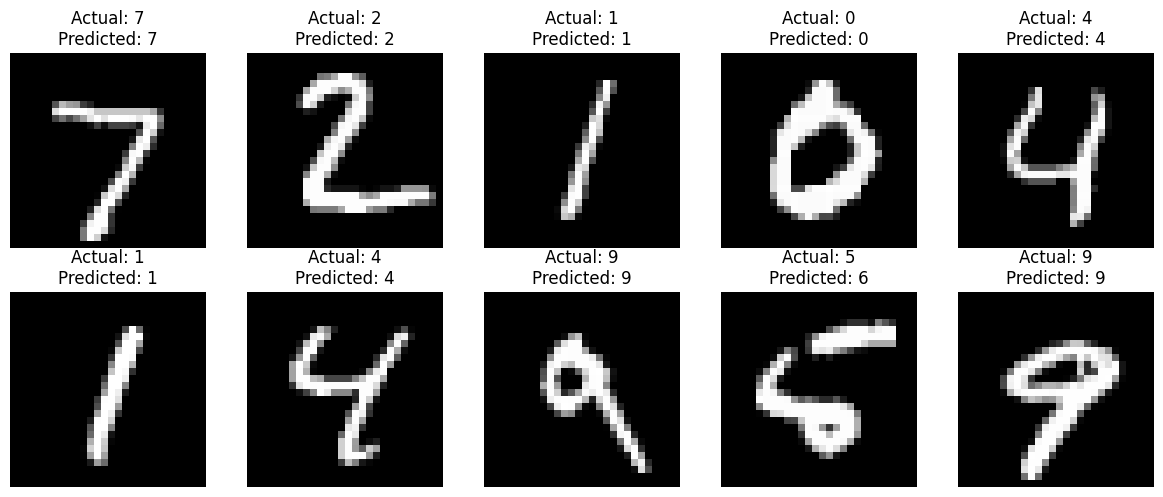

In [ ]:
probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

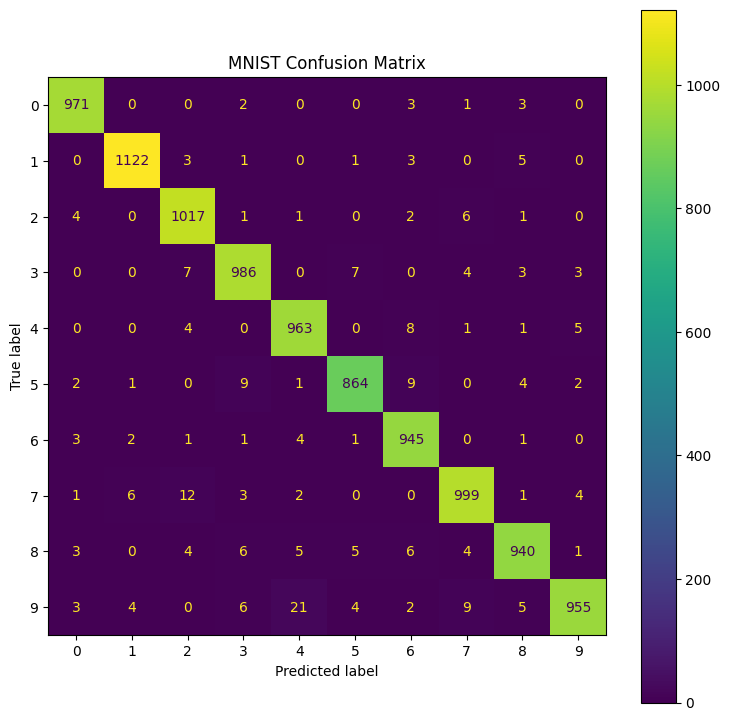

In [ ]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 9))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
).plot(ax=ax, values_format="d")

plt.title("MNIST Confusion Matrix")
plt.show()

Total incorrect predictions: 238


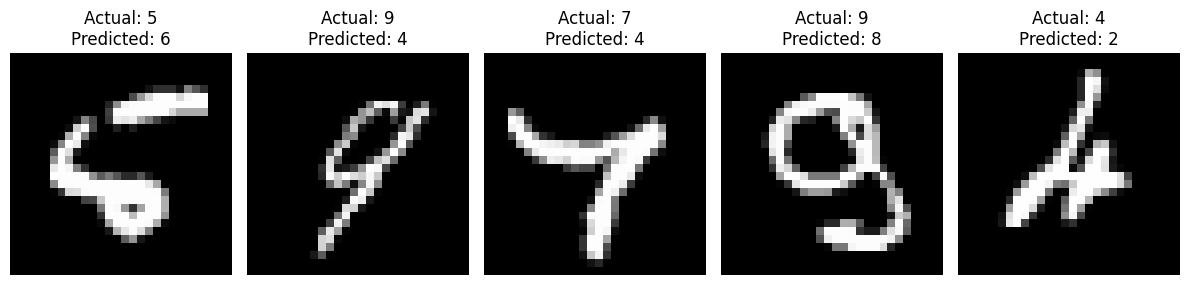

Actual: 5, Predicted: 6
Actual: 9, Predicted: 4
Actual: 7, Predicted: 4
Actual: 9, Predicted: 8
Actual: 4, Predicted: 2


In [ ]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Total incorrect predictions:", len(wrong_indices))

if len(wrong_indices) >= 5:
    plt.figure(figsize=(12, 4))

    for i, idx in enumerate(wrong_indices[:5]):
        plt.subplot(1, 5, i + 1)
        plt.imshow(x_test[idx], cmap="gray")
        plt.title(
            f"Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    for idx in wrong_indices[:5]:
        print(
            f"Actual: {y_test[idx]}, "
            f"Predicted: {y_pred[idx]}"
        )
else:
    print("Fewer than five errors were found.")

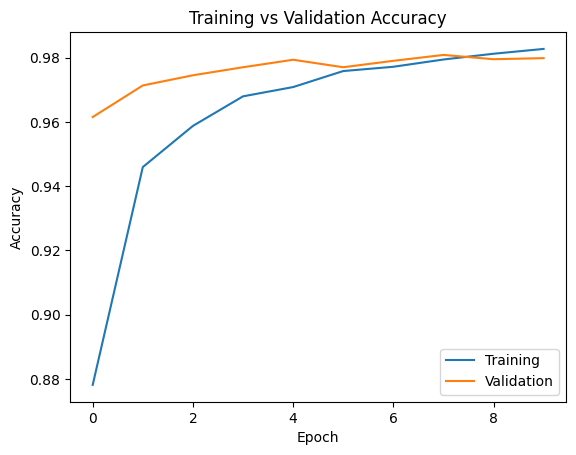

In [ ]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
model.save("mnist_digit_classifier.keras")
print("Model saved successfully!")

Model saved successfully!
